# AAI - Block 1 - Mini Symposium - Research - Model - Dutch

## 1. Packages Installeren

In [1]:
%pip install -qq matplotlib pandas tqdm ultralytics

Note: you may need to restart the kernel to use updated packages.


>In deze cel heb ik de Python-pakketten geïnstalleerd die nodig zijn voor de modelevaluatie. Het gaat onder andere om Matplotlib en Pandas voor gegevensverwerking en visualisatie, tqdm voor het weergeven van de voortgang en Ultralytics voor het laden en uitvoeren van het YOLOE-model.

## 2. Packages Importeren

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import torch
import platform
import sys
import ultralytics
import PIL

from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLOE

>In deze cel heb ik de benodigde bibliotheken geïmporteerd. Deze bibliotheken worden gebruikt voor numerieke berekeningen, het verwerken van tabellen, het meten van uitvoeringstijden, het controleren van de beschikbare hardware en het laden van het YOLOE-model.

## 3. Versies Controleren

In [ ]:
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("Pillow:", PIL.__version__)
print("CUDA beschikbaar:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA-versie (PyTorch):", torch.version.cuda)
else:
    print("GPU niet beschikbaar; evaluatie draait op CPU.")


Python: 3.14.6
Platform: macOS-26.6.2-arm64-arm-64bit-Mach-O
Ultralytics: 8.4.193
PyTorch: 2.14.1
Pillow: 13.0.0
CUDA beschikbaar: False
GPU niet beschikbaar; evaluatie draait op CPU.


> In deze cel heb ik de softwareomgeving gecontroleerd. Hierbij worden de versies van Python, Ultralytics, PyTorch en Pillow weergegeven. Ook wordt gecontroleerd of CUDA beschikbaar is en of de evaluatie op een GPU of CPU wordt uitgevoerd. De gebruikte omgeving bestaat uit Python 3.14.6, Ultralytics 8.4.193, PyTorch 2.14.1 en Pillow 13.0.0. CUDA is niet beschikbaar. De modelevaluatie wordt daarom uitgevoerd op de CPU van een macOS-systeem met ARM64-architectuur.

## 4. Model Configureren

In [ ]:
DATASET_DIR = Path("Dataset")
MODEL_WEIGHTS = "yoloe-26m-seg.pt"
CLASS_NAMES = [
    "book", "jersey", "sock", "sweater", "trousers", "underwear",
    "step_stool", "runner_(carpet)", "magazine", "shoe"
]
RESOLUTIONS = [320, 640, 1280]
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Benchmarkinstellingen: verhoog eventueel voor stabielere timing, maar vermeld dit in het artikel.
WARMUP_IMAGES = 5
TIMING_REPEATS = 3
CONF_THRESHOLD = 0.001
NMS_IOU_THRESHOLD = 0.7
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

if not Path(MODEL_WEIGHTS).is_file():
    raise FileNotFoundError(
        f"Modelgewichten niet gevonden: {Path(MODEL_WEIGHTS).resolve()}. "
        "Plaats yoloe-26m-seg.pt in de notebookmap of pas MODEL_WEIGHTS aan."
    )

model = YOLOE(MODEL_WEIGHTS)
model.set_classes(CLASS_NAMES)
print("Model:", MODEL_WEIGHTS)
print("Device:", DEVICE)
print("Klassen:", CLASS_NAMES)
print("Resoluties:", RESOLUTIONS)
print("Warm-up-afbeeldingen:", WARMUP_IMAGES)
print("Timingherhalingen per afbeelding:", TIMING_REPEATS)

/Users/gideon/Documents/Professional/Study/AAI/Block 1/Mini Symposium /mini_symposium_environment/lib/python3.14/site-packages/torch/jit/_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


Model: yoloe-26m-seg.pt
Device: cpu
Klassen: ['book', 'jersey', 'sock', 'sweater', 'trousers', 'underwear', 'step_stool', 'runner_(carpet)', 'magazine', 'shoe']
Resoluties: [320, 640, 1280]
Warm-up-afbeeldingen: 5
Timingherhalingen per afbeelding: 3


> In dit hoofdstuk heb ik de instellingen voor de modelevaluatie vastgelegd. Het yoloe-26m-seg.pt wordt geladen en gekoppeld aan de 10 geselecteerde objectcategorieën. Daarnaast zijn de drie invoerresoluties, het gebruikte rekendevice en de instellingen voor de benchmark vastgelegd. Er worden 5 afbeeldingen gebruikt voor de warm-up en de predictietijd wordt per afbeelding 3 keer gemeten. Ook is een vaste random seed ingesteld.

## 5. Testsets Controleren

In [5]:
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
testsets = {}

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset-map niet gevonden: {DATASET_DIR.resolve()}")

for size in RESOLUTIONS:
    folder = DATASET_DIR / f"Testset - {size}x{size}"
    images_dir, labels_dir = folder / "Afbeeldingen", folder / "Labels"
    if not images_dir.is_dir():
        images_dir, labels_dir = folder / "afbeeldingen", folder / "labels"
    images = sorted(p for p in images_dir.glob("*") if p.suffix.lower() in EXTENSIONS)
    if not images or not labels_dir.is_dir():
        raise FileNotFoundError(f"Controleer de afbeeldingen/labels in {folder}")
    missing = [p.name for p in images if not (labels_dir / f"{p.stem}.txt").exists()]
    if missing:
        raise FileNotFoundError(f"Labels ontbreken voor bijvoorbeeld: {missing[:5]}")
    testsets[size] = (images, labels_dir)
    print(f"{size}x{size}: {len(images)} afbeeldingen gevonden")

# Basiscontrole: de bestandsnamen moeten per resolutie overeenkomen.
name_sets = {size: {p.name for p in imgs} for size, (imgs, _) in testsets.items()}
reference_size = RESOLUTIONS[0]
for size in RESOLUTIONS[1:]:
    if name_sets[size] != name_sets[reference_size]:
        raise ValueError(
            f"Afbeeldingsnamen verschillen tussen {reference_size} en {size}. "
            "Controleer dat per resolutie exact dezelfde voorbeelden worden gebruikt."
        )
print("Controle geslaagd: dezelfde afbeeldingsbestandsnamen zijn aanwezig per resolutie.")


320x320: 100 afbeeldingen gevonden
640x640: 100 afbeeldingen gevonden
1280x1280: 100 afbeeldingen gevonden
Controle geslaagd: dezelfde afbeeldingsbestandsnamen zijn aanwezig per resolutie.


>In deze cel heb ik gecontroleerd of de testsets voor de drie resoluties aanwezig en volledig zijn. De code controleert of de afbeeldingsmappen en labelmappen bestaan, of iedere afbeelding een bijbehorend TXT-labelbestand heeft en of per resolutie dezelfde afbeeldingsbestanden worden gebruikt. Voor alle drie de resoluties zijn 100 afbeeldingen gevonden. Voor iedere afbeelding is een bijbehorend labelbestand aanwezig. De bestandsnamen komen tussen de resoluties overeen. De controle is daarmee succesvol afgerond voor in totaal 300 afbeeldingsbestanden en 300 bijbehorende labelbestanden, verdeeld over de drie testsets.

## 6. Functies Definieëren

In [6]:
def read_labels(path):
    boxes, classes = [], []
    for line in path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls, xc, yc, w, h = int(float(parts[0])), *map(float, parts[1:5])
        boxes.append([xc-w/2, yc-h/2, xc+w/2, yc+h/2])
        classes.append(cls)
    return np.array(boxes, dtype=float).reshape(-1, 4), np.array(classes, dtype=int)

def iou(box, boxes):
    if len(boxes) == 0:
        return np.zeros(0)
    left_top = np.maximum(box[:2], boxes[:, :2])
    right_bottom = np.minimum(box[2:], boxes[:, 2:])
    wh = np.clip(right_bottom-left_top, 0, None)
    inter = wh[:, 0] * wh[:, 1]
    area1 = max(0, box[2]-box[0]) * max(0, box[3]-box[1])
    area2 = np.clip(boxes[:, 2]-boxes[:, 0], 0, None) * np.clip(boxes[:, 3]-boxes[:, 1], 0, None)
    return inter / np.maximum(area1 + area2 - inter, 1e-12)

def ap101(recall, precision):
    recall = np.r_[0, recall, 1]
    precision = np.r_[0, precision, 0]
    for i in range(len(precision)-2, -1, -1):
        precision[i] = max(precision[i], precision[i+1])
    return np.mean([precision[recall >= r].max() if np.any(recall >= r) else 0 for r in np.linspace(0, 1, 101)])

def calculate_map(preds, truths):
    all_threshold_aps = []
    for threshold in np.arange(0.50, 0.951, 0.05):
        class_aps = []
        for cls in range(len(CLASS_NAMES)):
            total_gt = sum(np.sum(t["classes"] == cls) for t in truths)
            if total_gt == 0:
                continue
            detections = sorted(
                [(score, im, box) for im, p in enumerate(preds)
                 for box, score, c in zip(p["boxes"], p["scores"], p["classes"]) if c == cls],
                reverse=True, key=lambda x: x[0]
            )
            matched = [np.zeros(len(t["boxes"]), dtype=bool) for t in truths]
            tp, fp = [], []
            for score, im, box in detections:
                eligible = np.where(truths[im]["classes"] == cls)[0]
                overlaps = iou(box, truths[im]["boxes"][eligible])
                order = np.argsort(overlaps)[::-1]
                match = next((eligible[j] for j in order if overlaps[j] >= threshold and not matched[im][eligible[j]]), None)
                tp.append(match is not None)
                fp.append(match is None)
                if match is not None:
                    matched[im][match] = True
            if not detections:
                class_aps.append(0.0)
            else:
                tp, fp = np.cumsum(tp), np.cumsum(fp)
                class_aps.append(ap101(tp/total_gt, tp/np.maximum(tp+fp, 1e-12)))
        all_threshold_aps.append(np.mean(class_aps) if class_aps else np.nan)
    return all_threshold_aps[0], float(np.nanmean(all_threshold_aps))

> In deze cel heb ik alle benodigde functies gedefineërd voor de evaluatie van het YOLOE-25m-model.

## 7. Evaluatie Uitvoeren

In [7]:
rows = []
per_class_rows = []
timing_rows = []
all_run_metadata = []

def synchronize_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

for size, (images, labels_dir) in testsets.items():
    predictions, truths = [], []
    total_times_ms, inference_times_ms = [], []
    print(f"\\nEvaluatie {size}×{size}")

    # Warm-up op dezelfde resolutie; warm-upmetingen tellen niet mee in de resultaten.
    for warm_path in images[:min(WARMUP_IMAGES, len(images))]:
        _ = model.predict(
            str(warm_path), imgsz=size, device=DEVICE,
            conf=CONF_THRESHOLD, iou=NMS_IOU_THRESHOLD, verbose=False
        )
    synchronize_device()

    for image_path in tqdm(images, desc=f"{size}×{size}", unit="afbeelding"):
        gt_boxes, gt_classes = read_labels(labels_dir / f"{image_path.stem}.txt")
        truths.append({"boxes": gt_boxes, "classes": gt_classes})

        # Eén predictie voor de accuracy-metrics.
        result = model.predict(
            str(image_path), imgsz=size, device=DEVICE,
            conf=CONF_THRESHOLD, iou=NMS_IOU_THRESHOLD, verbose=False
        )[0]

        # Ultralytics rapporteert preprocessing, inference en postprocessing afzonderlijk.
        speed_info = getattr(result, "speed", {}) or {}
        inference_ms = speed_info.get("inference", np.nan)
        if inference_ms is not None and np.isfinite(inference_ms):
            inference_times_ms.append(float(inference_ms))

        boxes = result.boxes
        if boxes is None or len(boxes) == 0:
            pred_boxes = np.empty((0, 4))
            scores = np.empty(0)
            classes = np.empty(0, dtype=int)
        else:
            pred_boxes = boxes.xyxy.cpu().numpy().astype(float)
            h, w = result.orig_shape
            pred_boxes[:, [0, 2]] /= w
            pred_boxes[:, [1, 3]] /= h
            pred_boxes = np.clip(pred_boxes, 0, 1)
            scores = boxes.conf.cpu().numpy()
            classes = boxes.cls.cpu().numpy().astype(int)

        predictions.append({"boxes": pred_boxes, "scores": scores, "classes": classes})

        # Herhaalde wall-clock-metingen van de volledige predict-aanroep.
        # Synchroniseer vóór/na de aanroep om CUDA-asynchronie te ondervangen.
        for rep in range(TIMING_REPEATS):
            synchronize_device()
            start = time.perf_counter()
            timed_result = model.predict(
                str(image_path), imgsz=size, device=DEVICE,
                conf=CONF_THRESHOLD, iou=NMS_IOU_THRESHOLD, verbose=False
            )[0]
            synchronize_device()
            elapsed_ms = (time.perf_counter() - start) * 1000
            total_times_ms.append(elapsed_ms)

            timed_speed = getattr(timed_result, "speed", {}) or {}
            timed_infer = timed_speed.get("inference", np.nan)
            timing_rows.append({
                "Resolutie": f"{size}x{size}",
                "Afbeelding": image_path.name,
                "Herhaling": rep + 1,
                "Totale predictietijd (ms)": elapsed_ms,
                "Model-inferentie (ms)": float(timed_infer) if timed_infer is not None and np.isfinite(timed_infer) else np.nan,
                "Preprocessing (ms)": float(timed_speed.get("preprocess", np.nan)),
                "Postprocessing (ms)": float(timed_speed.get("postprocess", np.nan))
            })

    map50, map5095 = calculate_map(predictions, truths)

    total_arr = np.asarray(total_times_ms, dtype=float)
    infer_arr = np.asarray(inference_times_ms, dtype=float)
    mean_total = float(np.mean(total_arr))
    mean_infer = float(np.nanmean(infer_arr)) if len(infer_arr) and np.isfinite(infer_arr).any() else np.nan

    rows.append({
        "Resolutie": f"{size}x{size}",
        "Afbeeldingen": len(images),
        "mAP@50": map50,
        "mAP@50:95": map5095,
        "Totale predictietijd gem. (ms/afbeelding/run)": mean_total,
        "Totale predictietijd mediaan (ms)": float(np.median(total_arr)),
        "Totale predictietijd SD (ms)": float(np.std(total_arr, ddof=1)) if len(total_arr) > 1 else 0.0,
        "Model-inferentie gem. (ms/afbeelding)": mean_infer,
        "Model-inferentie mediaan (ms)": float(np.nanmedian(infer_arr)) if len(infer_arr) and np.isfinite(infer_arr).any() else np.nan,
        "Model-inferentie SD (ms)": float(np.nanstd(infer_arr, ddof=1)) if len(infer_arr) > 1 else np.nan,
        "Totale predictie-FPS": 1000 / mean_total if mean_total else np.nan,
        "Inferentie-FPS (benadering)": 1000 / mean_infer if mean_infer and np.isfinite(mean_infer) else np.nan
    })

    # Per klasse: aantal ground-truth-objecten; dit helpt lege/zeldzame klassen te herkennen.
    for cls_id, cls_name in enumerate(CLASS_NAMES):
        n_gt = int(sum(np.sum(t["classes"] == cls_id) for t in truths))
        n_pred = int(sum(np.sum(p["classes"] == cls_id) for p in predictions))
        per_class_rows.append({
            "Resolutie": f"{size}x{size}",
            "Klasse-ID": cls_id,
            "Klasse": cls_name,
            "Aantal ground-truth-objecten": n_gt,
            "Aantal voorspelde objecten": n_pred
        })

resultatentabel = pd.DataFrame(rows)
timingtabel = pd.DataFrame(timing_rows)
klassentabel = pd.DataFrame(per_class_rows)

print("Samenvatting per resolutie")
display(resultatentabel.round(4))
print("Aantal objecten per klasse en resolutie (diagnostiek; geen class-wise AP)")
display(klassentabel)


\nEvaluatie 320×320


320×320:   0%|          | 0/100 [00:00<?, ?afbeelding/s]

\nEvaluatie 640×640


640×640:   0%|          | 0/100 [00:00<?, ?afbeelding/s]

\nEvaluatie 1280×1280


1280×1280:   0%|          | 0/100 [00:00<?, ?afbeelding/s]

Samenvatting per resolutie


,Resolutie,Afbeeldingen,mAP@50,mAP@50:95,Totale predictietijd gem. (ms/afbeelding/run),Totale predictietijd mediaan (ms),Totale predictietijd SD (ms),Model-inferentie gem. (ms/afbeelding),Model-inferentie mediaan (ms),Model-inferentie SD (ms),Totale predictie-FPS,Inferentie-FPS (benadering)
0,320x320,100,0.1461,0.1064,135.6767,122.9679,39.1525,136.5876,118.2924,47.9576,7.3705,7.3213
1,640x640,100,0.2091,0.1492,468.7599,434.2040,101.1929,447.2940,412.0744,95.3657,2.1333,2.2357
2,1280x1280,100,0.1534,0.0898,2158.3950,2077.9827,293.3885,1975.0320,1946.0130,108.6525,0.4633,0.5063


Aantal objecten per klasse en resolutie (diagnostiek; geen class-wise AP)


,Resolutie,Klasse-ID,Klasse,Aantal ground-truth-objecten,Aantal voorspelde objecten
0,320x320,0,book,169,1183
1,320x320,1,jersey,59,72
2,320x320,2,sock,49,124
3,320x320,3,sweater,14,256
4,320x320,4,trousers,46,315
5,320x320,5,underwear,15,183
6,320x320,6,step_stool,10,94
7,320x320,7,runner_(carpet),13,361
8,320x320,8,magazine,56,0
9,320x320,9,shoe,57,295


> In deze cel heb ik het YOLOE-model geëvalueerd op de drie testsets. Per resolutie wordt eerst een warm-up uitgevoerd. Daarna worden de 100 afbeeldingen voorspeld en worden de voorspelde bounding boxes vergeleken met de ground-truth-labels. Op basis hiervan worden de mAP-scores berekend. Daarnaast worden de totale predictietijd en de model-inferentietijd gemeten. De timing wordt per afbeelding 3 keer herhaald. Ook worden de aantallen werkelijke en voorspelde objecten per klasse bijgehouden. De evaluatie is uitgevoerd op 100 afbeeldingen per resolutie, dus op 300 evaluaties van afbeeldingen over de drie resoluties. De behaalde detectiescores zijn als volgt:
>
> | Resolutie | mAP@50 | mAP@50:95 | Gemiddelde totale predictietijd |
>|:----------|-------:|----------:|--------------------------------:|
>| 320×320   | 0,1461 (14,61%) | 0,1064 (10,64%) | 135,68 ms |
>| 640×640   | 0,2091 (20,91%) | 0,1492 (14,92%) | 468,76 ms |
>| 1280×1280 | 0,1534 (15,34%) | 0,0898 (8,98%) | 2158,40 ms |
>
>De hoogste mAP@50 en mAP@50:95 zijn behaald bij de resolutie 640×640. De gemiddelde totale predictietijd is bij deze resolutie 468,76 milliseconden per afbeelding. De resolutie 320×320 heeft de kortste gemiddelde predictietijd met 135,68 milliseconden per afbeelding. De resolutie 1280×1280 heeft de langste gemiddelde predictietijd met 2158,40 milliseconden.
>
>In de ground-truth-labels zijn per testset dezelfde 488 objectannotaties aanwezig. De klasse book heeft met 169 annotaties de hoogste vertegenwoordiging en step_stool met 10 annotaties de laagste. De aantallen voorspelde objecten verschillen per resolutie en klasse. Deze aantallen zijn diagnostisch en vormen op zichzelf geen maat voor detectienauwkeurigheid.


## 8. Resultaten Visualiseren

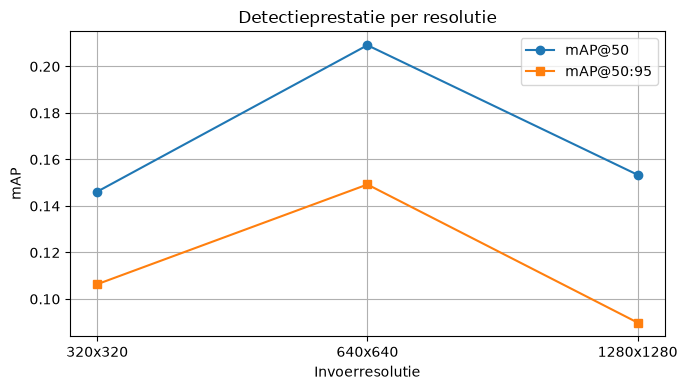

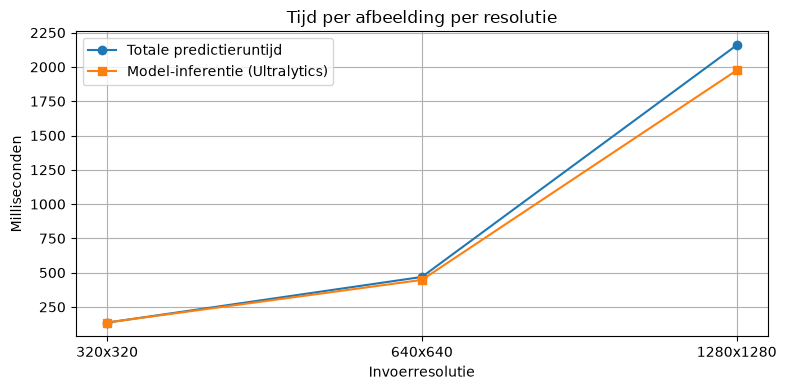

Opgeslagen: resultaten_resolutie_samenvatting.csv, resultaten_timing_per_afbeelding.csv, dataset_klasse_aantallen.csv


In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(resultatentabel["Resolutie"], resultatentabel["mAP@50"], marker="o", label="mAP@50")
ax.plot(resultatentabel["Resolutie"], resultatentabel["mAP@50:95"], marker="s", label="mAP@50:95")
ax.set(title="Detectieprestatie per resolutie", xlabel="Invoerresolutie", ylabel="mAP")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(resultatentabel["Resolutie"], resultatentabel["Totale predictietijd gem. (ms/afbeelding/run)"], marker="o", label="Totale predictieruntijd")
ax.plot(resultatentabel["Resolutie"], resultatentabel["Model-inferentie gem. (ms/afbeelding)"], marker="s", label="Model-inferentie (Ultralytics)")
ax.set(title="Tijd per afbeelding per resolutie", xlabel="Invoerresolutie", ylabel="Milliseconden")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

# Exporteer resultaten zodat tabellen/figuren in het artikel controleerbaar blijven.
resultatentabel.to_csv("resultaten_resolutie_samenvatting.csv", index=False)
timingtabel.to_csv("resultaten_timing_per_afbeelding.csv", index=False)
klassentabel.to_csv("dataset_klasse_aantallen.csv", index=False)
print("Opgeslagen: resultaten_resolutie_samenvatting.csv, resultaten_timing_per_afbeelding.csv, dataset_klasse_aantallen.csv")


>In dit hoofdstuk heb ik de evaluatieresultaten visueel weergegeven. De eerste grafiek vergelijkt de mAP@50- en mAP@50:95-scores tussen de drie invoerresoluties. De tweede grafiek vergelijkt de gemiddelde totale predictietijd met de gemiddelde model-inferentietijd. Tot slot worden de samenvatting, de timingmetingen en de aantallen per klasse als CSV-bestanden geëxporteerd. Er zijn 2 grafieken gegenereerd. De eerste grafiek laat zien dat 640×640 de hoogste detectiescores behaalt. De tweede grafiek laat zien dat de verwerkingstijd sterk toeneemt bij hogere resoluties. Daarnaast zijn 3 CSV-bestanden opgeslagen, namelijk resultaten_resolutie_samenvatting.csv, resultaten_timing_per_afbeelding.csv en dataset_klasse_aantallen.csv. Deze bestanden bevatten respectievelijk de samenvattende evaluatieresultaten, de timingmetingen per afbeelding en de aantallen objecten per klasse.